# Performing topic decomposition on sample simulated chromatin tracing data

Import required modules

In [1]:
from os import path
import numpy as np
import h5py
from topic3d.datatypes import PWDistArrayStack

## Loading the sample data

The training routine takes only arrays, so we will load the array from the dataset.

In [39]:
file_contents = h5py.File("./data/sample_experimental.h5")
file_contents.keys()

<KeysViewHDF5 ['bc_effs', 'pwds', 'traces']>

In [40]:
data_pwd = PWDistArrayStack(file_contents["pwds"][:])
data_pwd

PWDistArrayStack([[ 69.8641539 , 324.02469042, 130.98473193, ...,
                   225.1133048 , 284.83152915, 157.7624797 ],
                  [267.02247096, 333.6240399 , 199.71479665, ...,
                   206.00485431, 169.40484054, 155.45417331],
                  [209.02392208, 292.49957265, 299.64979559, ...,
                   111.7362967 , 256.60865145, 196.84765683],
                  ...,
                  [529.83110516, 259.43785383, 216.76484955, ...,
                   335.28793596, 365.05068141, 635.01023614],
                  [ 75.70997292, 166.09033687, 117.99152512, ...,
                            nan, 322.31351197,          nan],
                  [483.26597232, 186.86893803, 257.68973592, ...,
                            nan, 311.83328879,          nan]],
                 shape=(11631, 946))

The pairwise distance data has 9000 single-cell linearised maps (use `scipy.spatial.distance.squareform` to get a pairwise map).

In [41]:
data_pwd.shape

(11631, 946)

In [47]:
data_pwd_filt = PWDistArrayStack(data_pwd[::5])
data_pwd_filt

PWDistArrayStack([[ 69.8641539 , 324.02469042, 130.98473193, ...,
                   225.1133048 , 284.83152915, 157.7624797 ],
                  [ 56.69215113, 101.13851887, 131.88252348, ...,
                   501.8266633 , 367.20566444, 724.85998648],
                  [113.49449326, 119.47803145, 249.02409522, ...,
                   212.69931829, 328.79172739, 162.58228686],
                  ...,
                  [ 91.02197537, 168.54969594, 172.71074084, ...,
                   140.43503836, 290.14823798, 194.94101672],
                  [215.99305544,          nan, 303.56712602, ...,
                   208.90189085, 388.87915861, 476.15438673],
                  [483.26597232, 186.86893803, 257.68973592, ...,
                            nan, 311.83328879,          nan]],
                 shape=(2327, 946))

In [48]:
data_prox_filt = data_pwd_filt.proximity(threshold=150)

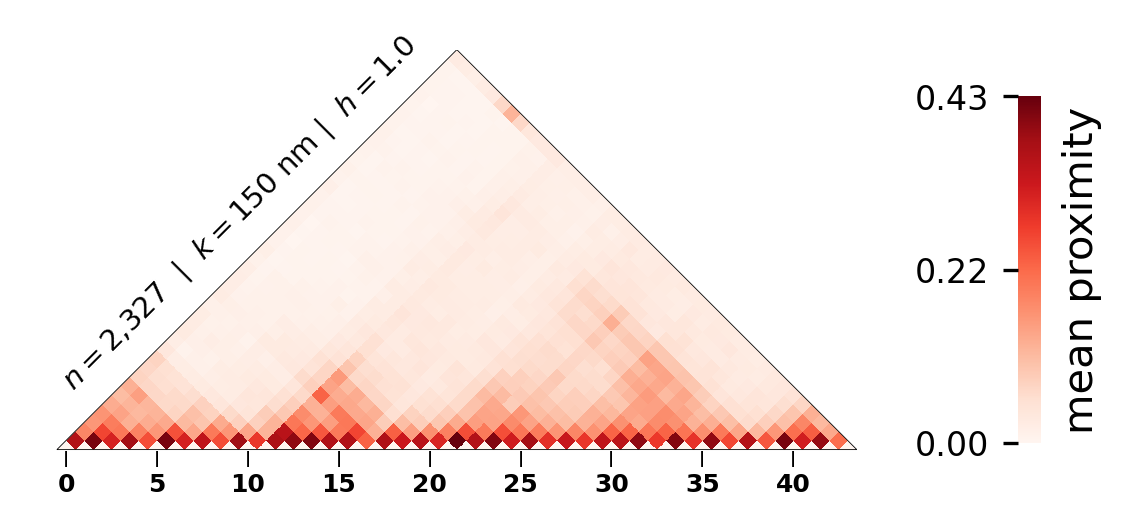

In [49]:
_ = data_pwd_filt.plot_proximity_avg(threshold=150)

In [50]:
from topic3d.workflow._dataops import split_proximity_data

In [54]:
data_prox_filt_train, data_prox_filt_test = split_proximity_data(data=data_prox_filt, train_data_proportion=0.75)

In [55]:
np.save("./data/sample_exp_train.npy", data_prox_filt_train)
np.save("./data/sample_exp_test.npy", data_prox_filt_test)

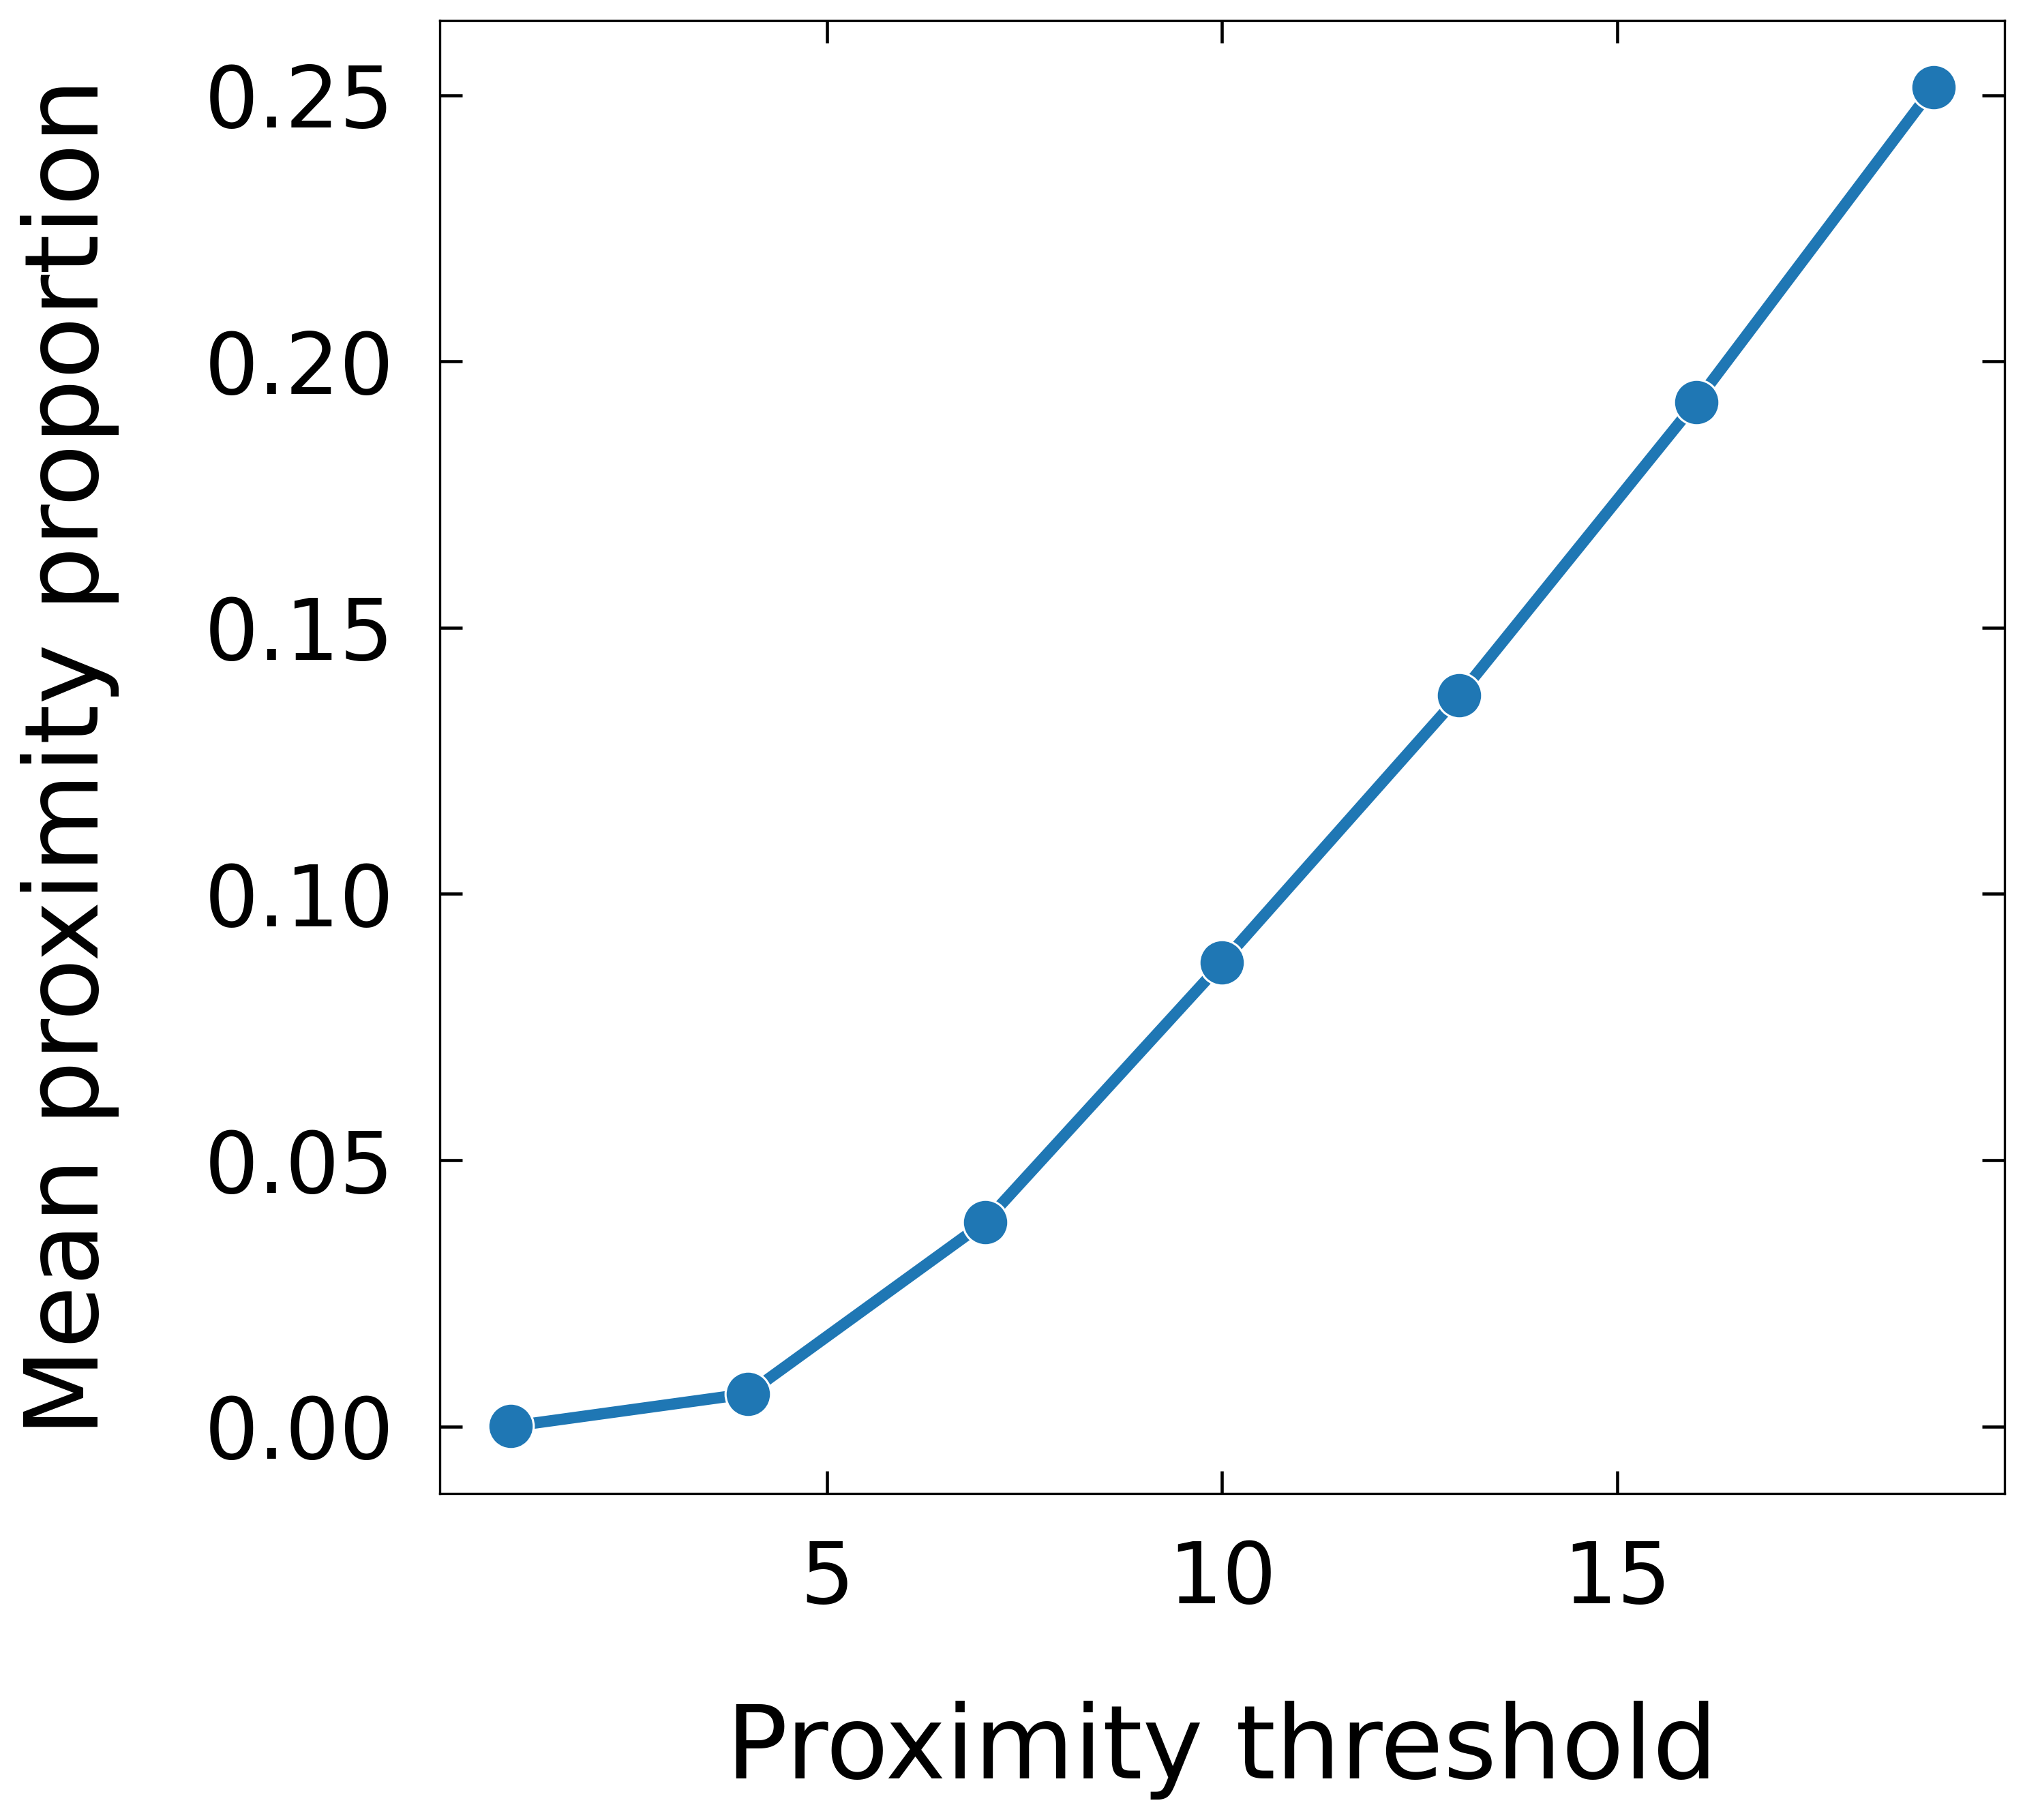

In [14]:
_ = data_pwd.plot_mean_proximity_proportion(thresholds=np.arange(1, 20, 3))

In [19]:
data_prox = data_pwd.proximity(threshold=10)

In [33]:
!topic3d-run \
        --data_file ./data/sample_simulated.h5 \
        --results_base_dir ./results/ \
        --save_logs \
        --proximity_threshold 10 \
        --num_components 5 \
        --max_iter 100 \
        --train_data_proportion 0.8

2026-02-20 19:27:49,105 [INFO] --------------------------------------------------
2026-02-20 19:27:49,105 [INFO] [f97e20] Will save trainings to: ./results/sample_simulated/05-components_threshold=10.0/f97e20
2026-02-20 19:27:49,105 [INFO] Settings summary for run: f97e20
2026-02-20 19:27:49,105 [INFO]     data_file: ./data/sample_simulated.h5
2026-02-20 19:27:49,105 [INFO]     results_base_dir: ./results/
2026-02-20 19:27:49,105 [INFO]     tag: sample_simulated
2026-02-20 19:27:49,105 [INFO]     save_logs: True
2026-02-20 19:27:49,105 [INFO]     proximity_threshold: 10.0
2026-02-20 19:27:49,106 [INFO]     proximity_hardness: 1
2026-02-20 19:27:49,106 [INFO]     pwd_normalization: None
2026-02-20 19:27:49,106 [INFO]     imputed: False
2026-02-20 19:27:49,106 [INFO]     min_efficiency: 0
2026-02-20 19:27:49,106 [INFO]     num_components: 5
2026-02-20 19:27:49,106 [INFO]     max_iter: 100
2026-02-20 19:27:49,106 [INFO]     learning_method: batch
2026-02-20 19:27:49,106 [INFO]     batch_s

In [21]:
params = {
    "data_file": "../data/sample_simulated.h5",
    "results_base_dir": "./",
    "save_logs": True,
    "proximity_threshold": 10,
    "min_efficiency": 0,
    "num_components": 5,
    "max_iter": 100,
    "train_data_proportion": 1
}